# Заняття 9 · LIVE DEMO 2
## Крос-камерна асоціація з розсинхроном годинників

**Постановка.** Дві камери з перекриттям зон покриття: A бачить `x ∈ [0, 60]` м, B — `x ∈ [45, 110]` м. У зоні перекриття `[45, 60]` м та сама ціль видна обом камерам одночасно, тож треки зшиваються **геометрично**: за відстанню між позиціями в метрах за однакових часових міток.

**Що ламаємо.** Годинник камери B зсунутий на `skew` секунд. Камера підписує кадр часом `t + skew`, і для рухомої цілі позиції «в той самий момент» розходяться на `v · skew` метрів.

**Що міряємо.** ID persistence — частку цілей, чий трек у A правильно зшито з треком у B (метрика прийомки для мережі щогл, розділ 01 «Постановка та метрики»).

Синтетика з відомим GT: позиції з шумом σ = 0.7 м, ембеддинги однотипних цілей навмисно схожі.

Мітка на слайдах: «ДЕМО 02 · lesson09_demo2_mtmc_clock_skew.ipynb» (розділ 05). Спільні графіки — у `panels.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from panels import PAL, set_style

set_style()
COL = {'пішохід': PAL['ok'], 'авто': PAL['bl'], 'дрон': PAL['or_']}

### 1. Сцена і спостереження камер

In [2]:
import numpy as np
from scipy.optimize import linear_sum_assignment

FPS = 10.0                   # частота треків на кожній камері, Гц
CAM_A = (0.0, 60.0)          # зона покриття камери A по осі x, м
CAM_B = (45.0, 110.0)        # зона покриття камери B; перекриття [45, 60] м
LANES = [0.0, 3.5, 7.0]      # смуги руху, м


def make_scene(n=24, speed=15.0, speed_jitter=0.15, headway=(1.0, 4.0), n_looks=6, look_spread=0.08, seed=0):
    """Об'єкти їдуть уздовж x через обидві зони. Однотипні цілі мають схожі ембеддинги:
    n_looks типів візуального опису, усередині кожного — невеликий розкид (look_spread)."""
    rng = np.random.default_rng(seed)
    looks = rng.normal(size=(n_looks, 64))
    looks /= np.linalg.norm(looks, axis=1, keepdims=True)
    objs, t0 = [], 0.0
    for k in range(n):
        t0 += rng.uniform(*headway)
        v = speed * (1 + rng.normal(0, speed_jitter))
        e = looks[rng.integers(n_looks)] + rng.normal(0, look_spread, 64)
        objs.append(dict(id=k, t0=t0, v=v, y=LANES[rng.integers(len(LANES))], emb=e / np.linalg.norm(e)))
    return objs


def observe(objs, cam, skew=0.0, pos_noise=0.7, emb_noise=0.10, seed=0):
    """Локальні треки камери в метрах. skew — зсув годинника камери, с:
    камера підписує кадр часом t_true + skew."""
    rng = np.random.default_rng(seed)
    x_lo, x_hi = cam
    tracks = []
    for o in objs:
        t_in, t_out = o['t0'] + (x_lo + 5) / o['v'], o['t0'] + (x_hi + 5) / o['v']
        ts = np.arange(np.ceil(t_in * FPS) / FPS, t_out, 1 / FPS)
        if len(ts) < 3:
            continue
        x = -5 + o['v'] * (ts - o['t0'])
        xy = np.c_[x + rng.normal(0, pos_noise, len(ts)), o['y'] + rng.normal(0, pos_noise, len(ts))]
        e = o['emb'] + rng.normal(0, emb_noise, 64)
        tracks.append(dict(gt=o['id'], t=ts + skew, xy=xy, emb=e / np.linalg.norm(e)))
    return tracks




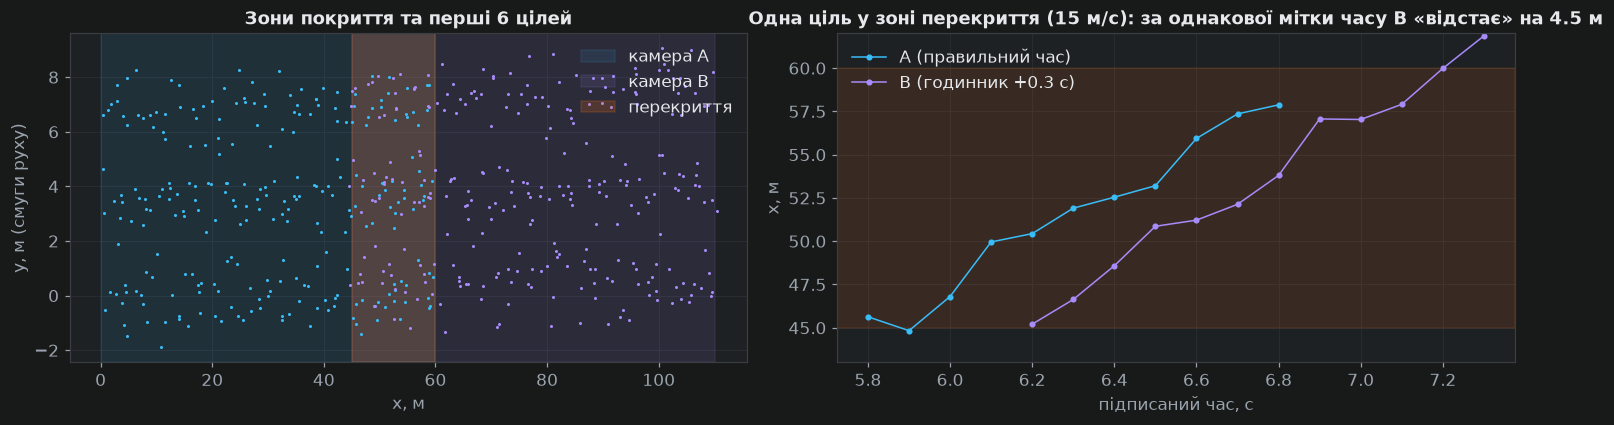

In [3]:
objs = make_scene(speed=15.0, seed=1)
A = observe(objs, CAM_A, skew=0.0, seed=1)
B = observe(objs, CAM_B, skew=0.3, seed=51)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].axvspan(*CAM_A, color=PAL['bl'], alpha=0.10, label='камера A')
ax[0].axvspan(*CAM_B, color=PAL['vi'], alpha=0.10, label='камера B')
ax[0].axvspan(45, 60, color=PAL['or_'], alpha=0.18, label='перекриття')
for tr in A[:6]:
    ax[0].plot(tr['xy'][:, 0], tr['xy'][:, 1], '.', ms=2, color=PAL['bl'])
for tr in B[:6]:
    ax[0].plot(tr['xy'][:, 0], tr['xy'][:, 1] + 0.4, '.', ms=2, color=PAL['vi'])
ax[0].set_xlabel('x, м'); ax[0].set_ylabel('y, м (смуги руху)'); ax[0].legend(loc='upper right')
ax[0].set_title('Зони покриття та перші 6 цілей')

g = A[0]['gt']
b = next(t for t in B if t['gt'] == g)
for tr, col, lab in [(A[0], PAL['bl'], 'A (правильний час)'), (b, PAL['vi'], 'B (годинник +0.3 с)')]:
    msk = (tr['xy'][:, 0] > 43) & (tr['xy'][:, 0] < 62)
    ax[1].plot(tr['t'][msk], tr['xy'][msk, 0], 'o-', ms=3, lw=1, color=col, label=lab)
ax[1].axhspan(45, 60, color=PAL['or_'], alpha=0.12)
ax[1].set_ylim(43, 62)
ax[1].set_xlabel('підписаний час, с'); ax[1].set_ylabel('x, м')
ax[1].set_title(f'Одна ціль у зоні перекриття (15 м/с): за однакової мітки часу B «відстає» на {15 * 0.3:.1f} м')
ax[1].legend(); plt.tight_layout(); plt.show()

### 2. Асоціація в зоні перекриття

`pair_cost` — медіанна відстань між треками за спільними (підписаними) мітками часу. `associate` — угорський алгоритм із **геометричним гейтом** `gate` (за замовчуванням 3 м) і опційною вагою візуального опису `w_app`.

In [4]:
def pair_cost(a, b, overlap=(45.0, 60.0)):
    """Середня відстань між треками в зоні перекриття за спільними (підписаними) часовими мітками."""
    ta = a['t'][(a['xy'][:, 0] >= overlap[0]) & (a['xy'][:, 0] <= overlap[1])]
    if len(ta) < 3:
        return np.inf
    lo, hi = max(ta.min(), b['t'].min()), min(ta.max(), b['t'].max())
    if hi - lo < 0.2:
        return np.inf
    tt = ta[(ta >= lo) & (ta <= hi)]
    pa = np.c_[np.interp(tt, a['t'], a['xy'][:, 0]), np.interp(tt, a['t'], a['xy'][:, 1])]
    pb = np.c_[np.interp(tt, b['t'], b['xy'][:, 0]), np.interp(tt, b['t'], b['xy'][:, 1])]
    return float(np.median(np.linalg.norm(pa - pb, axis=1)))


def associate(A, B, gate=3.0, w_app=0.0, skew_comp=0.0):
    """Геометричний гейт + (опційно) візуальний опис. skew_comp — оцінений зсув, який віднімаємо від часу B."""
    Bc = [dict(b, t=b['t'] - skew_comp) for b in B]
    D = np.array([[pair_cost(a, b) for b in Bc] for a in A])
    APP = np.array([[1 - a['emb'] @ b['emb'] for b in Bc] for a in A])
    cost = np.where(np.isfinite(D), D + w_app * 10 * APP, 1e6)
    r, c = linear_sum_assignment(cost)
    return [(i, j) for i, j in zip(r, c) if D[i, j] <= gate], D


def id_persistence(A, B, matches):
    """Частка GT-об'єктів, чий трек у A правильно зшито з треком у B."""
    gt_both = {a['gt'] for a in A} & {b['gt'] for b in B}
    ok = sum(1 for i, j in matches if A[i]['gt'] == B[j]['gt'])
    wrong = sum(1 for i, j in matches if A[i]['gt'] != B[j]['gt'])
    return ok / max(len(gt_both), 1), wrong




### 3. ID persistence залежно від розсинхрону і швидкості цілі

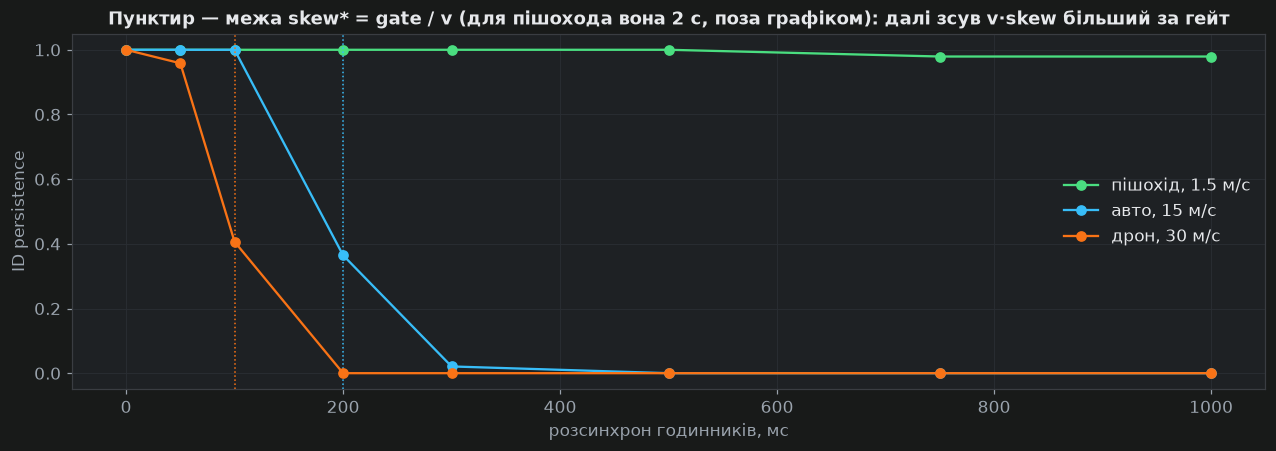

In [5]:
SKEWS = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]
CLASSES = {'пішохід': (1.5, (3, 10)), 'авто': (15.0, (1, 4)), 'дрон': (30.0, (1, 4))}
GATE = 3.0

res = {}
for name, (v, hw) in CLASSES.items():
    ys = []
    for sk in SKEWS:
        vals = []
        for sd in range(4):
            o = make_scene(speed=v, headway=hw, seed=sd)
            a = observe(o, CAM_A, 0.0, seed=sd)
            b = observe(o, CAM_B, sk, seed=sd + 50)
            m, _ = associate(a, b, gate=GATE)
            vals.append(id_persistence(a, b, m)[0])
        ys.append(np.mean(vals))
    res[name] = ys

plt.figure(figsize=(14, 4.2))
for name, ys in res.items():
    v = CLASSES[name][0]
    plt.plot(np.array(SKEWS) * 1000, ys, 'o-', color=COL[name], label=f'{name}, {v:g} м/с')
    if GATE / v <= max(SKEWS):
        plt.axvline(GATE / v * 1000, color=COL[name], ls=':', lw=1)
plt.xlabel('розсинхрон годинників, мс'); plt.ylabel('ID persistence')
plt.title('Пунктир — межа skew* = gate / v (для пішохода вона 2 с, поза графіком): далі зсув v·skew більший за гейт')
plt.legend(); plt.show()

**Що видно.** Для пішохода 1 с розсинхрону майже не шкодить (зсув 1.5 м < гейт 3 м). Для авто на 15 м/с межа — 200 мс, для дрона на 30 м/с — 100 мс. Той самий розрахунок, що на слайді: 100 км/год × 0.3 с ≈ 8.3 м.

### 4. «Просто розширимо гейт»?

Спокуса очевидна: якщо правильні пари не проходять гейт 3 м — зробити 12 м. Подивимось, що станеться при розсинхроні 0.6 с для авто: з'являються **хибні** зшивки між сусідніми цілями, а візуальний опис однотипних машин рятує лише частково.

In [6]:
rows = []
for gate, w_app, label in [(3.0, 0.0, 'гейт 3 м'), (12.0, 0.0, 'гейт 12 м'), (12.0, 1.0, 'гейт 12 м + візуальний опис')]:
    ok_l, bad_l = [], []
    for sd in range(6):
        o = make_scene(speed=15.0, seed=sd)
        a = observe(o, CAM_A, 0.0, seed=sd)
        b = observe(o, CAM_B, 0.6, seed=sd + 50)
        m, _ = associate(a, b, gate=gate, w_app=w_app)
        p, wrong = id_persistence(a, b, m)
        ok_l.append(p); bad_l.append(wrong / max(len(m), 1))
    rows.append((label, np.mean(ok_l), np.mean(bad_l)))

print(f"{'':30s} {'ID persistence':>15s} {'частка хибних зшивок':>22s}")
for label, p, w in rows:
    print(f'{label:30s} {p:15.2f} {w:22.2f}')

                                ID persistence   частка хибних зшивок
гейт 3 м                                  0.00                   0.33
гейт 12 м                                 0.52                   0.26
гейт 12 м + візуальний опис               0.56                   0.17


### 5. Лікування: оцінити зсув годинника з самих даних

Без жодних міток: перебираємо кандидатний зсув і шукаємо той, за якого взаємно найближчі пари треків мають мінімальну медіанну нев'язку. Це програмний аналог «стробоскопа в полі зору двох камер» зі слайда про синхронізацію.

In [7]:
def estimate_skew(A, B, grid=np.arange(-1.0, 1.0001, 0.02), gate=3.0):
    """Оцінка зсуву годинника без жодних міток: шукаємо зсув, при якому
    взаємно найближчі пари треків мають мінімальну медіанну нев'язку."""
    best, curve = None, []
    for s in grid:
        Bc = [dict(b, t=b['t'] - s) for b in B]
        D = np.array([[pair_cost(a, b) for b in Bc] for a in A])
        vals = []
        for i in range(len(A)):
            j = int(np.argmin(D[i]))
            if np.isfinite(D[i, j]) and int(np.argmin(D[:, j])) == i:
                vals.append(D[i, j])
        score = np.median(vals) if len(vals) >= 3 else np.inf
        curve.append(score)
        if best is None or score < best[1]:
            best = (s, score)
    return best[0], np.array(curve)


справжній зсув 300 мс, оцінений 320 мс
ID persistence: без компенсації 0.04, з компенсацією 1.00


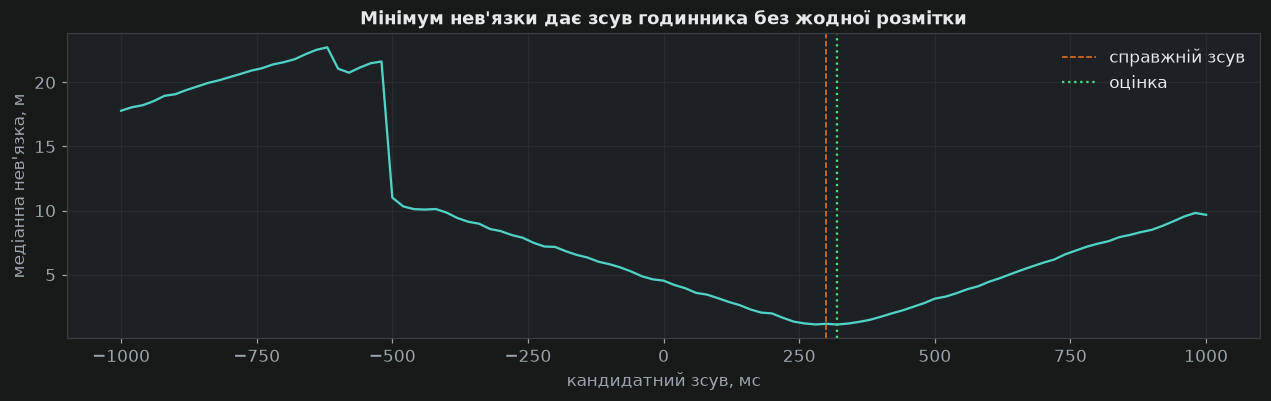

In [8]:
o = make_scene(speed=15.0, seed=3)
a = observe(o, CAM_A, 0.0, seed=3)
b = observe(o, CAM_B, 0.3, seed=53)
grid = np.arange(-1.0, 1.0001, 0.02)
s_hat, curve = estimate_skew(a, b, grid=grid)

m0, _ = associate(a, b, gate=3.0)
m1, _ = associate(a, b, gate=3.0, skew_comp=s_hat)
print(f'справжній зсув 300 мс, оцінений {s_hat * 1000:.0f} мс')
print(f'ID persistence: без компенсації {id_persistence(a, b, m0)[0]:.2f}, з компенсацією {id_persistence(a, b, m1)[0]:.2f}')

plt.figure(figsize=(14, 3.6))
plt.plot(grid * 1000, curve, color=PAL['te'])
plt.axvline(300, color=PAL['or_'], ls='--', lw=1, label='справжній зсув')
plt.axvline(s_hat * 1000, color=PAL['ok'], ls=':', lw=1.5, label='оцінка')
plt.xlabel('кандидатний зсув, мс'); plt.ylabel('медіанна нев\'язка, м')
plt.title('Мінімум нев\'язки дає зсув годинника без жодної розмітки')
plt.legend(); plt.show()

### Висновки для слайда
1. Точність MTMC визначається синхронізацією часу раніше, ніж якістю моделі ReID.
2. Межа розсинхрону — `gate / v`: для швидких цілей це десятки мілісекунд, а не секунди.
3. Розширений гейт міняє відмови на хибні зшивки; візуальний опис однотипних цілей рятує лише частково.
4. Зсув годинника оцінюється з самих треків — але це лікування симптому. Правильно — PTP / GNSS і timestamp на захопленні кадру.

### Місток до ДЗ
- Замініть геометричний гейт у зоні перекриття на **часове вікно переходу** для камер без перекриття. Як розсинхрон впливає тепер?
- Додайте оцінку зсуву як крок калібрування системи під час розгортання.